# Parte 1 — Red bayesiana: entrenamiento y validación temporal

**Proyecto final SI3003 · Vigilancia retrospectiva de dengue (Medellín y Apartadó)**

Este notebook entrena **desde cero** el modelo de la Parte 1 a partir de la base semanal y lo evalúa contra líneas base con una métrica cuantitativa. Todo el código del modelo está en `dengue_tools/entrenamiento.py` (implementación propia: discretización, CPT con Laplace, inferencia, calibración y selección de corte; no se usa ninguna librería de redes bayesianas).

Qué demuestra:

1. **Implementación propia**: Naive Bayes discreto (red bayesiana con la clase como padre de cada variable), inferencia exacta en espacio logarítmico y marginalización de faltantes.
2. **Validación temporal sin fuga de información**: 8 bloques de 13 semanas (2024–2025); cada bloque se predice solo con datos anteriores.
3. **Reproducibilidad**: los estados del modelo y las predicciones que usa la aplicación (`dengue_tools/data/`) se regeneran aquí y se comparan con `assert`.
4. **Métrica frente a línea base**: Brier, log-loss y balanced accuracy contra prevalencia y persistencia, con intervalo de confianza por bootstrap.

> Ejecutar desde la raíz del repositorio o desde `notebooks/`: *Run All*. No requiere GPU, API ni internet.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / 'dengue_tools').exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dengue_tools import entrenamiento as E

DATOS = RAIZ / 'dengue_tools' / 'data'
SALIDA = RAIZ / 'resultados'; SALIDA.mkdir(exist_ok=True)
pd.set_option('display.precision', 4)
COLORES = {'NB_casos_clima_cal': '#2a78d6', 'Persistencia_prob': '#eb6834',
           'Prevalencia': '#1baf7a', 'NB_casos_cal': '#eda100'}
print('Raíz del proyecto:', RAIZ.name)

Raíz del proyecto: IA_PROYECTO_FINAL


## 1. Datos

Base semanal por municipio con casos registrados de dengue (confirmados + probables) y clima agregado por semana epidemiológica. Las fuentes están documentadas en el `README.md` (sección *Datos y fuentes*). Se verifica la huella SHA-256 para garantizar que es exactamente la base con la que se ajustó el modelo que usa la aplicación.

In [2]:
base = E.cargar_base(DATOS / 'base_dengue_clima_semanal.csv')
paquete_guardado = json.loads((DATOS / 'estados_experimento.json').read_text(encoding='utf-8'))
assert E.sha256(DATOS / 'base_dengue_clima_semanal.csv') == paquete_guardado['sha256_base']
print('SHA-256 verificado. Filas:', len(base))
base.groupby('municipio').agg(semanas=('inicio_semana', 'size'), desde=('inicio_semana', 'min'),
                              hasta=('inicio_semana', 'max'), casos=('casos_registrados', 'sum'),
                              semanas_sin_temperatura=('temperatura_media_c', lambda s: s.isna().sum()),
                              semanas_sin_lluvia=('precipitacion_total_mm', lambda s: s.isna().sum()))

SHA-256 verificado. Filas: 418


,semanas,desde,hasta,casos,semanas_sin_temperatura,semanas_sin_lluvia
municipio,,,,,,
Apartadó,209,2022-01-02,2025-12-28,1759,2,2
Medellín,209,2022-01-02,2025-12-28,6780,0,0


## 2. Definición del evento

**Casos elevados** en la semana *t+1*: casos semanales **estrictamente mayores** que el percentil 75 de 2022–2023 del municipio. El umbral se fija con datos anteriores a todo el periodo evaluado (2024–2025).

In [3]:
umbrales = E.calcular_umbrales(base)
assert umbrales == paquete_guardado['umbrales_fijos']
print('Umbrales (P75 2022–2023):', umbrales)

v = E.construir_variables(base, umbrales)
validas = E.transiciones_validas(v)
(validas.assign(ano=validas.ano_objetivo.astype(int))
        .groupby(['municipio', 'ano']).y.agg(semanas='size', prevalencia='mean').unstack('municipio'))

Umbrales (P75 2022–2023): {'05001': 7.25, '05045': 9.0}


semanas          prevalencia         
municipio Apartadó Medellín    Apartadó Medellín
ano                                             
2022            48       48      0.0625   0.0417
2023            52       52      0.4038   0.4423
2024            52       52      0.3269   1.0000
2025            53       53      0.6038   0.9811

Observación clave: en **Medellín la prevalencia del evento salta de ~25 % (2022–2023) a ~99 % en 2024–2025** (epidemia de 2024: el umbral fijo de 7.25 casos quedó superado casi todas las semanas). En Medellín la tarea de evaluación es casi trivial y su balanced accuracy pierde sentido (casi no hay negativos). **El caso informativo es Apartadó**, con prevalencia cercana al 47 %.

## 3. Variables y modelo

Para la semana de origen *t* (predictores) y objetivo *t+1*:

| Variable | Definición |
|---|---|
| `casos_actuales` | casos registrados en *t* |
| `cambio_casos` | casos en *t* menos el promedio de las **tres** semanas anteriores |
| `lluvia_4s` | precipitación acumulada de cuatro semanas (incluye *t*) |
| `temperatura_4s` | temperatura media de cuatro semanas (incluye *t*) |

**Naive Bayes discreto** (red bayesiana donde *y* es el único padre de cada variable):

$$P(y \mid x_1,\dots,x_k) \;\propto\; P(y)\prod_{j} P(x_j \mid y)$$

- Cada variable se discretiza en 3 categorías con los **terciles del entrenamiento** de ese municipio y bloque.
- **Suavizado de Laplace** (α = 1) en el prior y en cada CPT: $P(x=k\mid y)=\dfrac{n_{k,y}+1}{n_y+3}$.
- Un dato faltante se **marginaliza** (la variable no aporta factor); no se imputa con cero.
- Dos redes: `NB_casos` (solo casos) y `NB_casos_clima` (casos + clima), cada una con versión calibrada (`_cal`).

**Líneas base**: `Prevalencia` (frecuencia histórica del evento), `Persistencia` (la semana siguiente repite el estado actual) y `Persistencia_prob` (P(y<sub>t+1</sub>=1 | estado<sub>t</sub>) estimada con transiciones históricas — una cadena de Markov de dos estados).

Ejemplo: CPT de la red con clima para Medellín en el primer bloque (filas = clase y, columnas = tercil).

In [4]:
ent_b1 = validas[validas.fecha_objetivo.lt(pd.Timestamp('2023-12-31'))]
estado = E.ajustar_nb(ent_b1[ent_b1.codigo_municipio.eq('05001')], E.VARIABLES['NB_casos_clima'])
print('Prior P(y):', np.round(estado['prior'], 4))
pd.concat({var: pd.DataFrame(spec['cpt'], index=['y=0', 'y=1'], columns=['bajo', 'medio', 'alto'])
           for var, spec in estado['variables'].items()}, axis=1).round(3)

Prior P(y): [0.7451 0.2549]


casos_actuales               cambio_casos               lluvia_4s         \
              bajo  medio   alto         bajo  medio   alto      bajo  medio   
y=0          0.385  0.346  0.269        0.333  0.321  0.346     0.308  0.308   
y=1          0.107  0.143  0.750        0.321  0.286  0.393     0.393  0.393   

           temperatura_4s                
      alto           bajo  medio   alto  
y=0  0.385          0.423  0.346  0.231  
y=1  0.214          0.071  0.286  0.643

## 4. Validación temporal (walk-forward)

Para cada bloque de 13 semanas de 2024–2025:

1. **Entrenamiento**: transiciones cuyo objetivo es anterior al inicio del bloque (ventana creciente).
2. **Calibración logística** $p' = \sigma(a\,\mathrm{logit}(p)+b)$, ajustada con las predicciones fuera de muestra de los bloques anteriores (log-loss medio + 0.01·((a−1)²+b²), es decir, regularizada hacia la identidad). Solo se activa con historial ≥ 40 semanas y ≥ 10 por clase.
3. **Corte de clasificación**: el valor de una rejilla 0.05…0.95 que maximiza la balanced accuracy del historial (empates → el más cercano a 0.5; sin historial suficiente → 0.5).
4. **Evaluación** en el bloque, que el modelo nunca vio.

In [5]:
paquete, pred, auditoria = E.validacion_temporal(base)
assert (auditoria.fin_entrenamiento < auditoria.inicio_evaluacion).all(), 'fuga temporal'
(auditoria[auditoria.modelo.eq('NB_casos_clima_cal')]
 [['bloque', 'n_entrenamiento', 'n_evaluacion', 'n_historial', 'fin_entrenamiento', 'inicio_evaluacion',
   'calibracion_activa', 'a', 'b', 'corte']].reset_index(drop=True))

,bloque,n_entrenamiento,n_evaluacion,n_historial,fin_entrenamiento,inicio_evaluacion,calibracion_activa,a,b,corte
0,2024_B1,200,26,0,2023-12-24,2023-12-31,False,1.0000,0.0000,0.50
1,2024_B2,226,26,26,2024-03-24,2024-03-31,False,1.0000,0.0000,0.50
2,2024_B3,252,26,52,2024-06-23,2024-06-30,True,0.8985,0.5649,0.65
3,2024_B4,278,26,78,2024-09-22,2024-09-29,True,1.3210,0.0993,0.70
4,2025_B1,304,26,104,2024-12-22,2024-12-29,True,1.2076,0.1707,0.70
5,2025_B2,330,26,130,2025-03-23,2025-03-30,True,0.9549,0.5864,0.70
6,2025_B3,356,26,156,2025-06-22,2025-06-29,True,0.9902,0.8373,0.70
7,2025_B4,382,28,182,2025-09-21,2025-09-28,True,0.9041,0.8476,0.55


## 5. Reproducibilidad: comparación con los artefactos que usa la aplicación

La aplicación carga `estados_experimento.json` y `predicciones_temporales.csv` ya ajustados. Aquí se comprueba que se obtienen **los mismos** valores al reentrenar desde la base.

In [6]:
dif_cpt = dif_cal = dif_corte = 0.0
for nuevo, guardado in zip(paquete['estados_por_bloque'], paquete_guardado['estados_por_bloque']):
    assert nuevo['bloque'] == guardado['bloque']
    for red in E.VARIABLES:
        for cod, est in nuevo['redes'][red]['estados'].items():
            ref = guardado['redes'][red]['estados'][cod]
            dif_cpt = max(dif_cpt, np.abs(np.subtract(est['prior'], ref['prior'])).max())
            for var, spec in est['variables'].items():
                dif_cpt = max(dif_cpt, np.abs(np.subtract(spec['cpt'], ref['variables'][var]['cpt'])).max(),
                              np.abs(np.subtract(spec['cortes'], ref['variables'][var]['cortes'])).max())
        c_new, c_ref = nuevo['calibradores'][red], guardado['calibradores'][red]
        assert c_new['activa'] == c_ref['activa']
        dif_cal = max(dif_cal, abs(c_new['a'] - c_ref['a']), abs(c_new['b'] - c_ref['b']))
    dif_corte = max(dif_corte, max(abs(nuevo['cortes'][m] - guardado['cortes'][m]) for m in E.MODELOS))

ref = pd.read_csv(DATOS / 'predicciones_temporales.csv', dtype={'codigo_municipio': str}, parse_dates=['fecha_objetivo'])
cmp = pred.merge(ref, on=['codigo_municipio', 'fecha_objetivo', 'modelo'], suffixes=('', '_ref'))
assert len(cmp) == len(ref) == len(pred)
assert dif_cpt == 0 and dif_corte == 0 and dif_cal < 1e-3
assert (cmp.p - cmp.p_ref).abs().max() < 1e-4 and (cmp.pred_ajustado == cmp.pred_ajustado_ref).all()
print(f'CPT, priors y cortes de discretización: diferencia máxima {dif_cpt}')
print(f'Calibración (a, b): diferencia máxima {dif_cal:.1e} (tolerancia del optimizador)')
print(f'Cortes de clasificación: diferencia máxima {dif_corte}')
print(f'Predicciones: {len(cmp)} filas, |p − p_guardada| máx {(cmp.p - cmp.p_ref).abs().max():.1e}, '
      f'clasificaciones distintas {int((cmp.pred_ajustado != cmp.pred_ajustado_ref).sum())}')

CPT, priors y cortes de discretización: diferencia máxima 0.0
Calibración (a, b): diferencia máxima 1.8e-05 (tolerancia del optimizador)
Cortes de clasificación: diferencia máxima 0.0
Predicciones: 1470 filas, |p − p_guardada| máx 5.1e-06, clasificaciones distintas 0


## 6. Métricas frente a las líneas base

- **Brier** = media de (p − y)²: la métrica principal, porque evalúa la probabilidad, que es lo que muestra el dashboard (menor es mejor).
- **Log-loss**: penaliza fuertemente probabilidades extremas equivocadas.
- **Balanced accuracy** con el corte ajustado: promedio de sensibilidad y especificidad (robusta al desbalance).

In [7]:
tabla = E.metricas(pred).sort_values('brier')
tabla['brier_skill_vs_prevalencia'] = 1 - tabla.brier / tabla.loc['Prevalencia', 'brier']
tabla.to_csv(SALIDA / 'metricas_modelos.csv')
tabla.round(4)

,n,prevalencia,brier,log_loss,balanced_accuracy,sensibilidad,especificidad,accuracy_05,brier_skill_vs_prevalencia
modelo,,,,,,,,,
Persistencia_prob,210.0,0.7286,0.1225,0.4039,0.8347,0.9150,0.7544,0.8714,0.5832
Persistencia,210.0,0.7286,0.1286,1.7763,0.8347,0.9150,0.7544,0.8714,0.5625
NB_casos_clima_cal,210.0,0.7286,0.1436,0.4429,0.7442,0.7516,0.7368,0.8000,0.5114
NB_casos_cal,210.0,0.7286,0.1514,0.4537,0.6870,0.8301,0.5439,0.7714,0.4849
NB_casos_clima,210.0,0.7286,0.1553,0.4706,0.7423,0.6601,0.8246,0.7762,0.4716
NB_casos,210.0,0.7286,0.1622,0.4772,0.7671,0.7974,0.7368,0.7476,0.4479
Prevalencia,210.0,0.7286,0.2938,0.7904,0.6321,0.5098,0.7544,0.5143,0.0000


In [8]:
por_municipio = E.metricas(pred, por=('municipio', 'modelo'))
por_municipio.to_csv(SALIDA / 'metricas_por_municipio.csv')
por_municipio[['n', 'prevalencia', 'brier', 'log_loss', 'balanced_accuracy']].round(4)

n  prevalencia   brier  log_loss  \
municipio modelo                                                     
Apartadó  NB_casos            105.0       0.4667  0.2213    0.6305   
          NB_casos_cal        105.0       0.4667  0.2349    0.6859   
          NB_casos_clima      105.0       0.4667  0.2367    0.6923   
          NB_casos_clima_cal  105.0       0.4667  0.2418    0.7113   
          Persistencia        105.0       0.4667  0.2381    3.2894   
          Persistencia_prob   105.0       0.4667  0.1976    0.5884   
          Prevalencia         105.0       0.4667  0.2847    0.7722   
Medellín  NB_casos            105.0       0.9905  0.1032    0.3239   
          NB_casos_cal        105.0       0.9905  0.0678    0.2214   
          NB_casos_clima      105.0       0.9905  0.0738    0.2489   
          NB_casos_clima_cal  105.0       0.9905  0.0453    0.1745   
          Persistencia        105.0       0.9905  0.0190    0.2632   
          Persistencia_prob   105.0       0.9905  0.0473    0.2195   
          Prevalencia         105.0       0.9905  0.3030    0.8087   

                              balanced_accuracy  
municipio modelo                                 
Apartadó  NB_casos                       0.6607  
          NB_casos_cal                   0.6135  
          NB_casos_clima                 0.5638  
          NB_casos_clima_cal             0.5689  
          Persistencia                   0.7615  
          Persistencia_prob              0.7615  
          Prevalencia                    0.3839  
Medellín  NB_casos                       0.4519  
          NB_casos_cal                   0.4519  
          NB_casos_clima                 0.9135  
          NB_casos_clima_cal             0.4615  
          Persistencia                   0.4952  
          Persistencia_prob              0.4952  
          Prevalencia                    0.3750

**¿Es significativa la diferencia con la mejor línea base?** Bootstrap por bloques móviles de 4 semanas (respeta la autocorrelación semanal), pareado por semana y municipio.

In [9]:
filas = []
for a, b in [('NB_casos_clima_cal', 'Persistencia_prob'), ('NB_casos_clima_cal', 'Prevalencia'),
             ('NB_casos_clima_cal', 'NB_casos_cal')]:
    d, lo, hi = E.bootstrap_diferencia_brier(pred, a, b, n=2000)
    filas.append({'comparación': f'{a} − {b}', 'Δ Brier': d, 'IC95 inferior': lo, 'IC95 superior': hi,
                  'conclusión': 'a mejor' if hi < 0 else ('b mejor' if lo > 0 else 'no significativa')})
ic = pd.DataFrame(filas); ic.to_csv(SALIDA / 'bootstrap_brier.csv', index=False)
ic.round(4)

,comparación,Δ Brier,IC95 inferior,IC95 superior,conclusión
0,NB_casos_clima_cal − Persistencia_prob,0.0211,-0.0079,0.0512,no significativa
1,NB_casos_clima_cal − Prevalencia,-0.1503,-0.2035,-0.0997,a mejor
2,NB_casos_clima_cal − NB_casos_cal,-0.0078,-0.0393,0.0231,no significativa


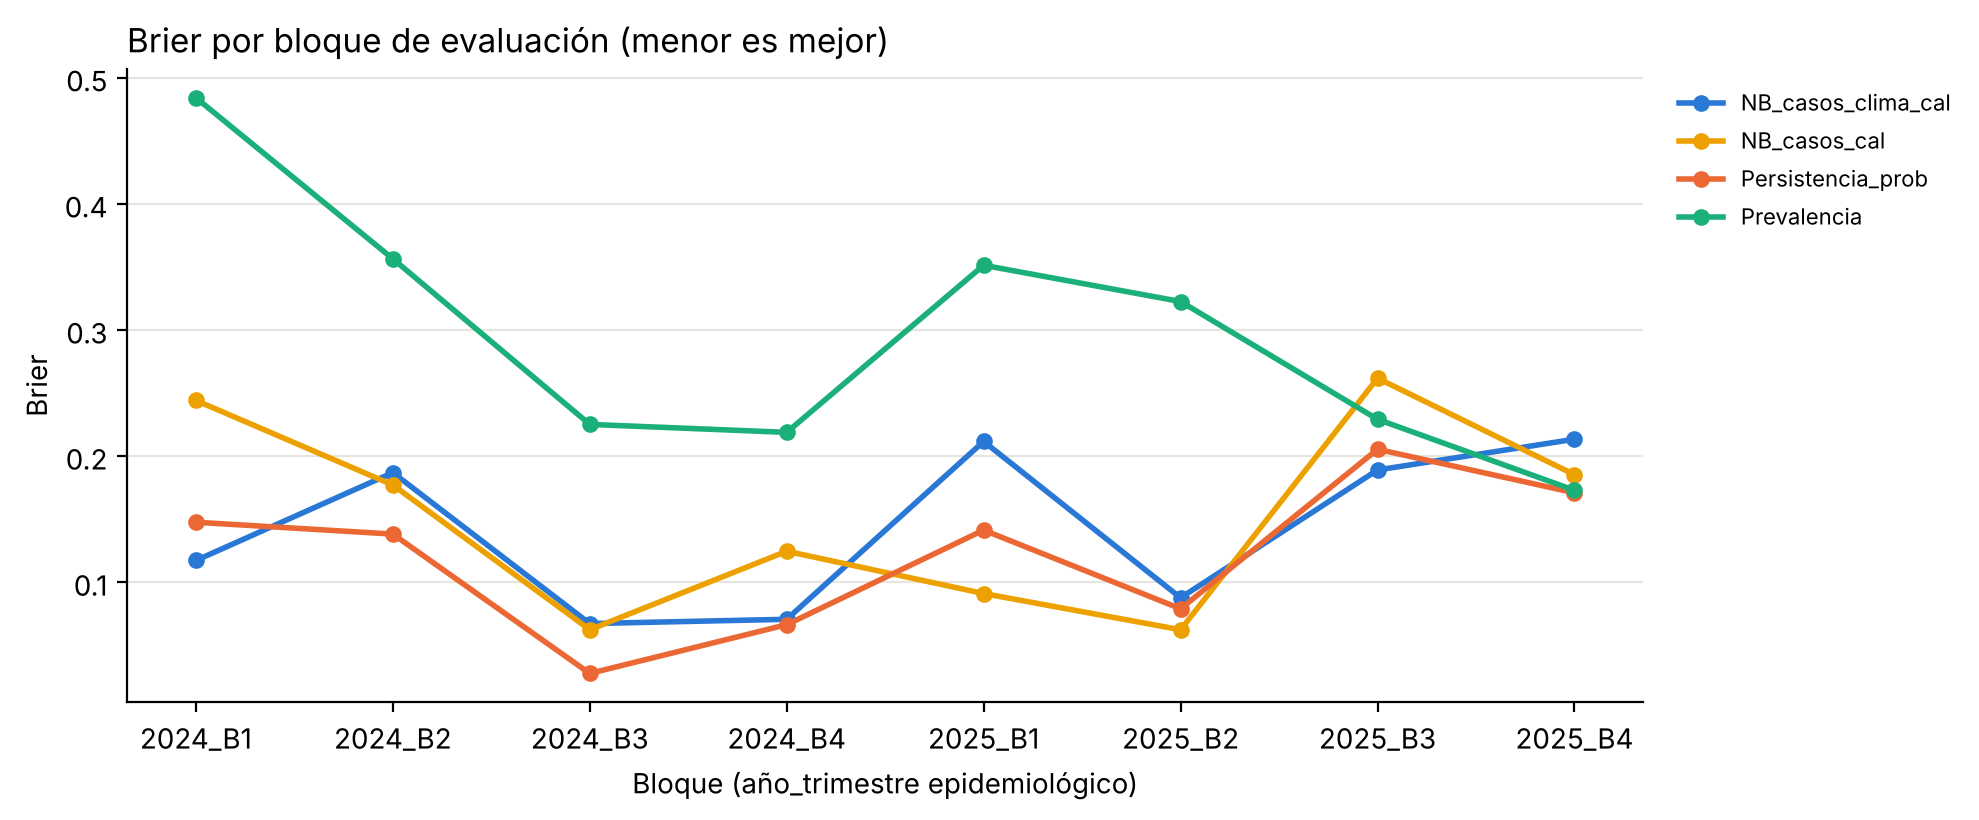

modelo,NB_casos_cal,NB_casos_clima_cal,Persistencia_prob,Prevalencia
bloque,,,,
2024_B1,0.244,0.117,0.148,0.484
2024_B2,0.177,0.187,0.138,0.356
2024_B3,0.062,0.067,0.028,0.225
2024_B4,0.125,0.071,0.066,0.219
2025_B1,0.091,0.212,0.141,0.351
2025_B2,0.062,0.088,0.079,0.322
2025_B3,0.262,0.189,0.205,0.229
2025_B4,0.185,0.213,0.171,0.173


In [10]:
modelos_graf = ['NB_casos_clima_cal', 'NB_casos_cal', 'Persistencia_prob', 'Prevalencia']
brier_bloque = (pred[pred.modelo.isin(modelos_graf)].assign(err=lambda d: (d.p - d.y) ** 2)
                .groupby(['bloque', 'modelo']).err.mean().unstack())
fig, ax = plt.subplots(figsize=(10, 4.2))
for m in modelos_graf:
    ax.plot(brier_bloque.index, brier_bloque[m], marker='o', ms=5, lw=2, color=COLORES[m], label=m)
ax.set_title('Brier por bloque de evaluación (menor es mejor)', loc='left')
ax.set_xlabel('Bloque (año_trimestre epidemiológico)'); ax.set_ylabel('Brier')
ax.grid(axis='y', color='#e6e5e0'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(SALIDA / 'brier_por_bloque.png', dpi=150); plt.show()
brier_bloque.round(3)

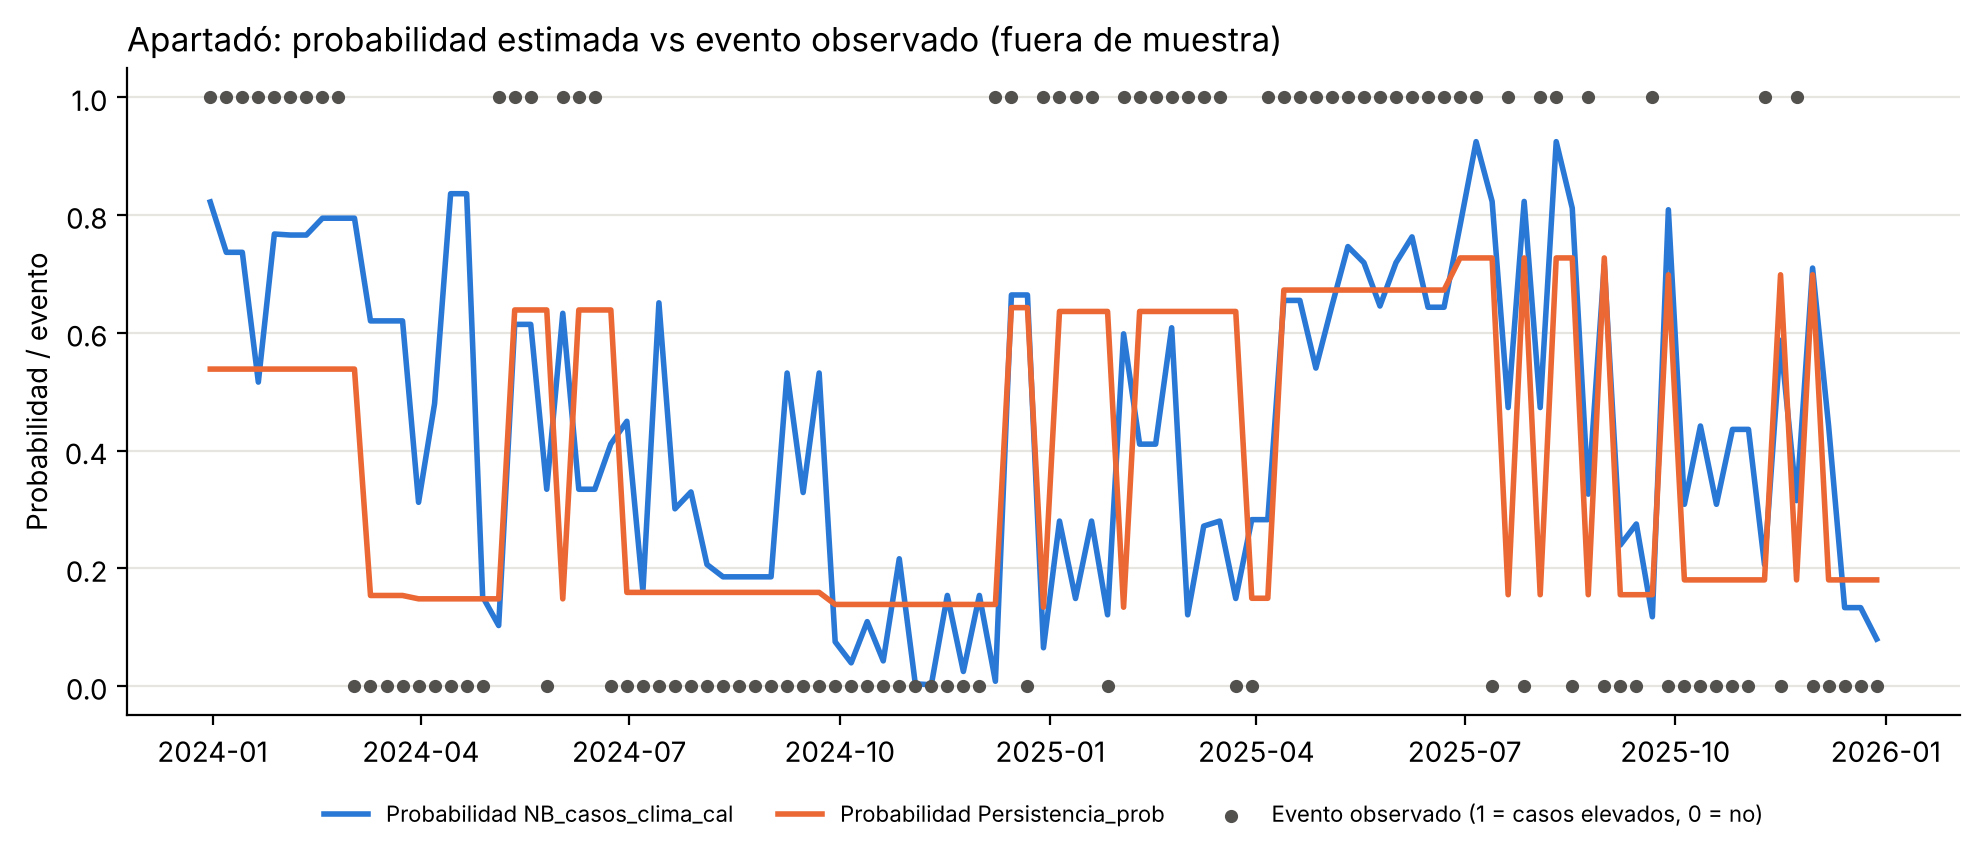

In [11]:
apa = pred[pred.municipio.eq('Apartadó')]
fig, ax = plt.subplots(figsize=(10, 4.4))
for m in ['NB_casos_clima_cal', 'Persistencia_prob']:
    s = apa[apa.modelo.eq(m)]
    ax.plot(s.fecha_objetivo, s.p, lw=2, color=COLORES[m], label=f'Probabilidad {m}')
obs = apa[apa.modelo.eq('Prevalencia')]
ax.scatter(obs.fecha_objetivo, obs.y, s=14, color='#52514e', label='Evento observado (1 = casos elevados, 0 = no)', zorder=3)
ax.set_title('Apartadó: probabilidad estimada vs evento observado (fuera de muestra)', loc='left')
ax.set_ylabel('Probabilidad / evento'); ax.set_ylim(-0.05, 1.05)
ax.grid(axis='y', color='#e6e5e0'); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.tight_layout(); plt.savefig(SALIDA / 'apartado_probabilidad_vs_evento.png', dpi=150); plt.show()

## 7. Interpretación y limitaciones

Lectura de las tablas anteriores (los valores exactos salen de las celdas ejecutadas):

- **Contra la línea base débil (prevalencia)** la red bayesiana es claramente mejor: Brier ≈ 0.144 contra ≈ 0.294 (*Brier skill* ≈ 0.51), con un intervalo de confianza que excluye el cero.
- **Contra la línea base fuerte (persistencia probabilística)** la red **no gana**: Brier ≈ 0.144 contra ≈ 0.123. El bootstrap muestra que la diferencia (≈ +0.02) **no es estadísticamente significativa** (el IC 95 % incluye el cero). Con datos semanales muy autocorrelacionados, "la semana siguiente se parece a esta" es una línea base difícil de superar a un paso.
- **En el agregado, clima y calibración parecen ayudar** (`NB_casos_clima_cal` ≈ 0.144 contra `NB_casos_cal` ≈ 0.151 y `NB_casos_clima` ≈ 0.155), **pero esa mejora viene de Medellín**. El bootstrap de `NB_casos_clima_cal − NB_casos_cal` no es significativo: no hay evidencia de que el clima mejore la predicción a una semana.
- **En Apartadó (el caso informativo) ocurre lo contrario**: el mejor Naive Bayes es el más simple, `NB_casos` (Brier ≈ 0.221), y agregar clima y calibración lo empeora (`NB_casos_clima_cal` ≈ 0.242). Explicación probable: la calibración es **global** (un solo par a, b para ambos municipios) y el historial está dominado por Medellín, con prevalencia ≈ 99 %, lo que empuja las probabilidades hacia arriba también en Apartadó. Una calibración por municipio es la mejora natural.
- **Medellín es casi degenerado**: con prevalencia ≈ 99 % en 2024–2025, cualquier modelo que diga "sí" acierta; su balanced accuracy no es informativa (hay un solo negativo).
- **La persistencia probabilística es la mejor en ambos municipios** (Apartadó ≈ 0.198): a un paso, el estado actual es el mejor predictor del siguiente.

Limitaciones: dos municipios; análisis retrospectivo con datos consolidados (no reproduce el retraso real de notificación); umbral fijo que no se adapta a cambios de régimen (epidemia de 2024); calibración agrupada entre municipios; horizonte de una semana. **Superar el umbral del proyecto no es una alerta oficial ni una declaración de brote.**

Trabajo futuro sugerido por estos resultados: calibración por municipio, umbral móvil (p. ej., percentil de las últimas 52 semanas) y combinar la persistencia con el Naive Bayes (por ejemplo, `estado_actual` como variable adicional de la red).

In [12]:
pred.to_csv(SALIDA / 'predicciones_reentrenadas.csv', index=False)
print('Resultados guardados en', SALIDA.relative_to(RAIZ), '->', sorted(p.name for p in SALIDA.iterdir()))

Resultados guardados en resultados -> ['apartado_probabilidad_vs_evento.png', 'bootstrap_brier.csv', 'brier_por_bloque.png', 'metricas_modelos.csv', 'metricas_por_municipio.csv', 'predicciones_reentrenadas.csv']
